# Set Up
1. Necessary imports that will be used throughout the entire file.
2. Read the data set from Kaggle. (CSV file)

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# webtoon_originals_en.csv
df = pd.read_csv("webtoon_originals_en.csv", na_filter = False)

# Looking at the Table

helpful commands (debug):

df.shape
df.columns
df.head()
df.tail()
df.info()

df["some_column"].unique()
df["some_column"].value_counts()
df["some_column"].min()
df["some_column"].max()

In [136]:
print(df.shape)
print(df.columns)

# Removing the title_id rating, and synopsis columns.
df = df[["title", "genre", "authors", "weekdays", "length", "subscribers", "views", "likes", "status"]]
display(df.head(5))

(2277, 12)
Index(['title_id', 'title', 'genre', 'authors', 'weekdays', 'length',
       'subscribers', 'rating', 'views', 'likes', 'status', 'synopsis'],
      dtype='str')


,title,genre,authors,weekdays,length,subscribers,views,likes,status
0,The Grudge,ROMANCE,Kuaikan Comics,SATURDAY,4,262,1529,46,ONGOING
1,Junk to King: I Am A Scavenger,ACTION,"Dong Yiffy,King,Youma Wenhua,BILIBILI COMICS",FRIDAY,6,2840,19514,989,COMPLETED
2,Elixir of the Sun,ROMANCE,"one,Song Yi,Sung U Hyun,Solddam",THURSDAY,3,2559,15181,782,COMPLETED
3,Deadman's Undecember,ACTION,FanFan Comic,MONDAY,9,1136,3263,278,ONGOING
4,24-Hour Rebirth Consultation Center,FANTASY,"Yeseong,nokum,Cheong Ahan","MONDAY,TUESDAY,WEDNESDAY,THURSDAY,FRIDAY,SATUR...",4,9057,51487,3722,COMPLETED


# Cleaning Data:

In [137]:
df.info() # get the general info

(df == "").sum() # bc of na_filter = false, we need to check for empty strings.

df.duplicated().sum()

# df[["length", "subscribers", "views", "likes"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 2277 entries, 0 to 2276
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        2277 non-null   str  
 1   genre        2277 non-null   str  
 2   authors      2277 non-null   str  
 3   weekdays     2277 non-null   str  
 4   length       2277 non-null   int64
 5   subscribers  2277 non-null   int64
 6   views        2277 non-null   int64
 7   likes        2277 non-null   int64
 8   status       2277 non-null   str  
dtypes: int64(4), str(5)
memory usage: 160.2 KB


np.int64(0)

Everything is pretty much good. Looks clean and no NaN or empty strings.

# GENRE : 

In [138]:
# How many unique genres are there?
# How many number of each genre in the dataset?

print(f"There are {df['genre'].nunique()} unique genres in this dataset.")
display(df["genre"].value_counts())

There are 17 unique genres in this dataset.


genre
ROMANCE          666
FANTASY          392
ACTION           391
DRAMA            204
COMEDY           119
THRILLER         113
SLICE_OF_LIFE     76
SUPERNATURAL      63
SF                54
HORROR            48
SUPER_HERO        37
GRAPHIC_NOVEL     36
SPORTS            27
MYSTERY           23
HISTORICAL        12
TIPTOON            8
HEARTWARMING       8
Name: count, dtype: int64

genre
SLICE_OF_LIFE    5.752397e+07
SUPER_HERO       4.508982e+07
COMEDY           3.580672e+07
Name: views, dtype: float64

C:\Users\Harry\AppData\Local\Temp\ipykernel_26096\2058582903.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_views.index, y=avg_views.values, palette="husl")


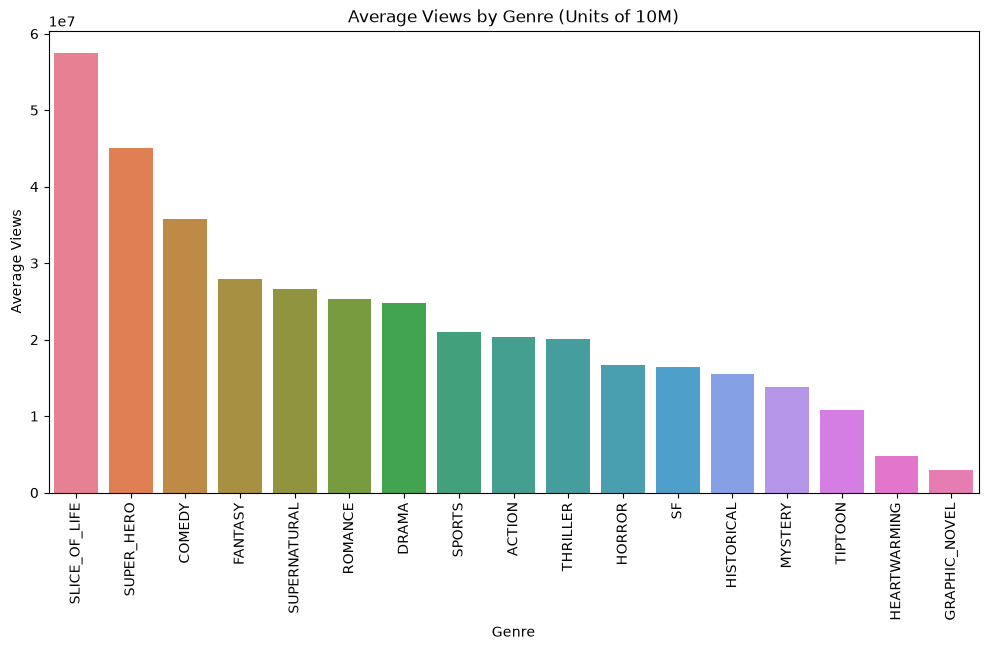

In [ ]:
# What is the average of views by Genre?

# Display Top 3 Genres with Highest Average Views sorted in Descending Order

avg_views = df.groupby("genre")["views"].mean().sort_values(ascending = False)
display(avg_views[0:3])

# Plot the Bar Chart :
plt.figure(figsize = (12,6))

# colors:
colors = sns.color_palette("husl", len(avg_views))

sns.barplot(x=avg_views.index, y=avg_views.values, palette="husl")
plt.title("Average Views by Genre (Units of 10M)")
plt.xlabel("Genre")
plt.ylabel("Average Views")
plt.xticks(rotation=90)
plt.show()

genre
SLICE_OF_LIFE    4.789276e+06
COMEDY           3.001405e+06
SUPER_HERO       2.477437e+06
Name: likes, dtype: float64

C:\Users\Harry\AppData\Local\Temp\ipykernel_26096\527123390.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_likes.index, y=avg_likes.values, palette="husl")


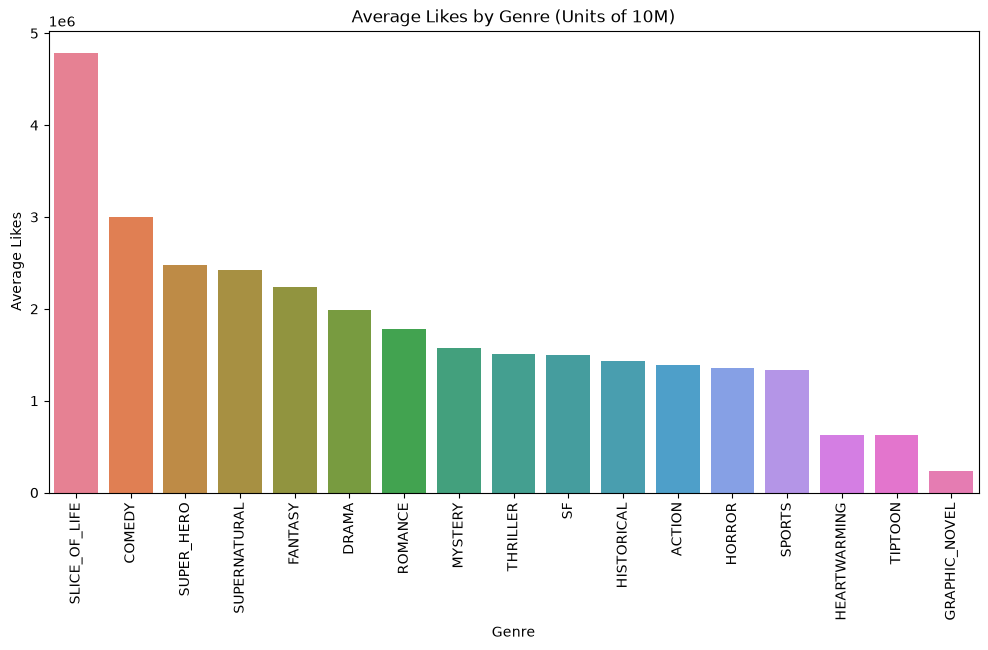

In [143]:
# What is the average of likes by Genre?

# Display Top 3 Genres with Highest Average Likes sorted in Descending Order

avg_likes = df.groupby("genre")["likes"].mean().sort_values(ascending = False)
display(avg_likes[0:3])

# Plot the Bar Chart :
plt.figure(figsize = (12,6))

# colors:
colors = sns.color_palette("husl", len(avg_likes))

sns.barplot(x=avg_likes.index, y=avg_likes.values, palette="husl")
plt.title("Average Likes by Genre (Units of 10M)")
plt.xlabel("Genre")
plt.ylabel("Average Likes")
plt.xticks(rotation=90)
plt.show()

# Generic Questions

In [ ]:
# Top 10 Webtoons with Most Views

top_10 = df.sort_values(by = "views", ascending = False).head(10)
top_10 = top_10[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(top_10) 

,title,genre,authors,subscribers,views,likes,status
2061,Lore Olympus,ROMANCE,Rachel Smythe,6649628,1427726818,72888685,COMPLETED
2140,unOrdinary,SUPER_HERO,uru-chan,6299250,1397987835,71369756,ONGOING
2246,Tower of God,FANTASY,SIU,4221200,1288045134,66332771,HIATUS
2103,Lookism,DRAMA,Taejun Pak,3847160,1071346830,59347796,ONGOING
2041,True Beauty,ROMANCE,Yaongyi,7545593,1036981207,55811728,COMPLETED
2116,My Giant Nerd Boyfriend,SLICE_OF_LIFE,fishball,2402091,856721498,79456119,ONGOING
2274,The God of High School,ACTION,Dragon j,2981789,799518634,31887388,COMPLETED
2112,I Love Yoo,DRAMA,Quimchee,4751323,645598010,40207660,ONGOING
1948,Down To Earth,ROMANCE,Pookie Senpai,4419082,619301663,28960248,HIATUS
2236,Bluechair,SLICE_OF_LIFE,Shen,1435565,604636242,51462556,COMPLETED


In [ ]:
# Top 10 Webtoons with Least Views

bottom_10 = df.sort_values(by = "views", ascending = True).head(10)
bottom_10 = bottom_10[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(bottom_10) 

,title,genre,authors,subscribers,views,likes,status
0,The Grudge,ROMANCE,Kuaikan Comics,262,1529,46,ONGOING
112,The Amazing Spider-Man: Big Time,ACTION,Marvel,1006,1610,113,ONGOING
3,Deadman's Undecember,ACTION,FanFan Comic,1136,3263,278,ONGOING
2,Elixir of the Sun,ROMANCE,"one,Song Yi,Sung U Hyun,Solddam",2559,15181,782,COMPLETED
1,Junk to King: I Am A Scavenger,ACTION,"Dong Yiffy,King,Youma Wenhua,BILIBILI COMICS",2840,19514,989,COMPLETED
365,Vigilante 2,THRILLER,"kim kyusam,CRG",7329,24465,1265,COMPLETED
96,Taka,ACTION,IDW Publishing,5887,25221,3117,HIATUS
162,Star Wars™: The Legends of Luke Skywalker - Th...,SF,Lucasfilm Ltd.,5700,25379,2741,ONGOING
190,Stitch in Time,FANTASY,"Disney,Adriano Barone,Fabrizio Cosentino",5964,31792,2643,ONGOING
54,Devils' Crest,FANTASY,"REKI KAWAHARA,Takano Koroku,TO Moe",4663,34020,1327,ONGOING
